# HRPD: synthetic-to-real bearing fault diagnosis with healthy-only target data

This notebook walks through **HRPD (Healthy-Referenced Physics-informed Diagnosis)** end to end on a miniature MFPT dataset bundled with the repository.

The setting: the labelled training **source** is synthetic (fault impulse trains injected into real healthy carrier windows), the **target** machine contributes healthy recordings only, and the real faults are used exclusively for the final test. No real fault sample is seen during training, adaptation, or model selection.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from hrpd import (DATASETS, HRPDConfig, load_base5, phys_features,
                  two_channel, train_hrpd, compute_metrics)

spec = DATASETS["mfpt"]
data = load_base5("data", "mfpt", seed=0)
print(f"classes: {spec.class_names}")
print(f"synthetic source: {data.Xs.shape}, target-train healthy: {data.Xtt.shape}, test: {data.Xte.shape}")
print(f"characteristic orders: BPFO={spec.bpfo}, BPFI={spec.bpfi}, BSF={spec.bsf} (ball line at 2xBSF)")

classes: ('Normal', 'IR', 'OR')
synthetic source: (3600, 1000), target-train healthy: (70, 1000), test: (770, 1000)
characteristic orders: BPFO=3.245, BPFI=4.755, BSF=2.5546 (ball line at 2xBSF)


## 1. The envelope-order spectra

Every sample is an envelope-order spectrum on a uniform shaft-order grid [0, 30]. A bearing fault appears as a harmonic series at its geometry-derived characteristic order. Compare the class means of the synthetic source with the real test classes:

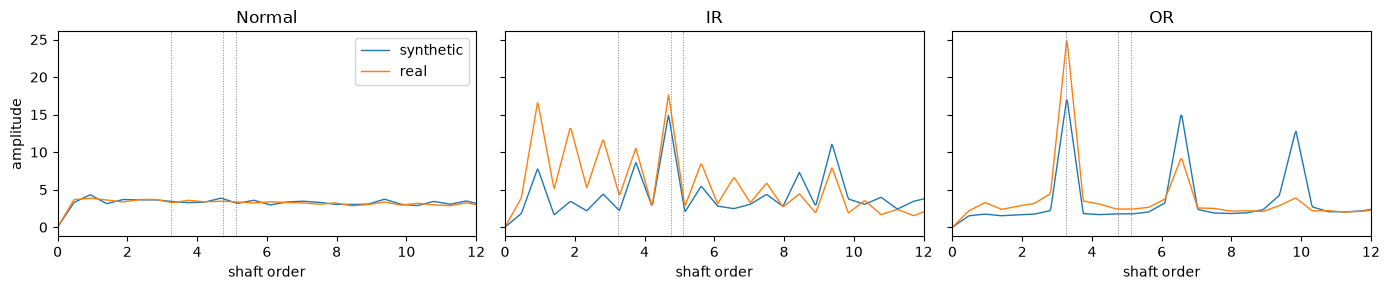

In [2]:
grid = np.linspace(0, 30, data.Xs.shape[1])
fig, axes = plt.subplots(1, len(spec.class_names), figsize=(14, 3), sharey=True)
for c, (ax, name) in enumerate(zip(axes, spec.class_names)):
    ax.plot(grid, data.Xs[data.ys == c].mean(0), label="synthetic", lw=1)
    ax.plot(grid, data.Xte[data.yte == c].mean(0), label="real", lw=1)
    for o in (spec.bpfo, spec.bpfi, 2 * spec.bsf):
        ax.axvline(o, color="gray", ls=":", lw=0.7)
    ax.set_xlim(0, 12); ax.set_title(name); ax.set_xlabel("shaft order")
axes[0].set_ylabel("amplitude"); axes[0].legend()
plt.tight_layout()

## 2. The two inputs HRPD consumes

**Two-channel input** `u(x) = [x - healthy_baseline, log(1+x)]`: the residual channel suppresses the class-shared healthy component (estimated once per domain from healthy data only), the log channel keeps the full spectral structure.

**Wide-window physics feature**: the maximum of the spectrum over a ±10% window around the first 10 harmonics of BPFO, BPFI, BSF (30 values, RMS-normalised; harmonics falling above order 30 are zero-filled).

two-channel input: (3, 2, 1000) | physics feature: (3, 30)


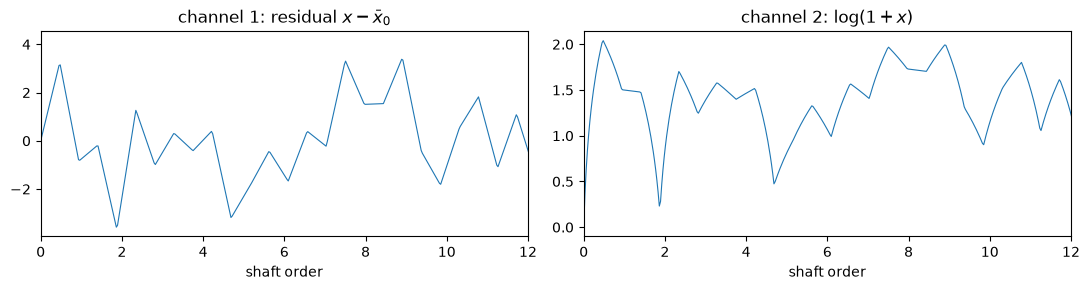

In [3]:
baseline = data.Xtt.mean(0)                       # target healthy baseline
u = two_channel(data.Xte[:3], baseline)            # (3, 2, 1000)
phi = phys_features(data.Xte[:3], (spec.bpfo, spec.bpfi, spec.bsf))
print("two-channel input:", u.shape, "| physics feature:", phi.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(grid, u[0, 0], lw=0.8); axes[0].set_title("channel 1: residual $x-\\bar{x}_0$")
axes[1].plot(grid, u[0, 1], lw=0.8); axes[1].set_title("channel 2: $\\log(1+x)$")
for ax in axes: ax.set_xlabel("shaft order"); ax.set_xlim(0, 12)
plt.tight_layout()

## 3. Train HRPD

The pipeline: source pre-training (Mixup cross-entropy on cosine-prototype logits + SupCon) -> adaptation (adds the healthy-class-restricted adversarial term) -> prototype shift -> AdaBN -> frozen inference.

For the demo we use a short schedule; the paper configuration is `epochs_pretrain=120, epochs_adapt=160` with five seeds.

In [4]:
cfg = HRPDConfig(epochs_pretrain=60, epochs_adapt=80,
                 device="cuda" if torch.cuda.is_available() else "cpu")
probs, model = train_hrpd(data, spec, cfg, seed=0)
print("test probabilities:", probs.shape)

test probabilities: (770, 3)


## 4. Evaluate on the real faults

balanced accuracy: 0.986
  recall Normal: 0.957
  recall     IR: 1.000
  recall     OR: 1.000


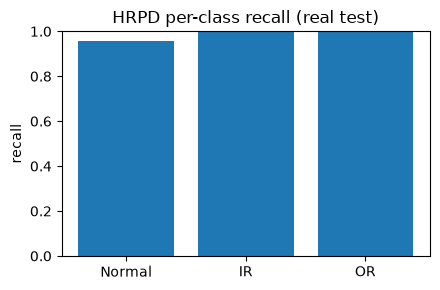

In [5]:
metrics = compute_metrics(probs, data.yte, spec.n_classes)
print(f"balanced accuracy: {metrics['balanced_accuracy']:.3f}")
for name, r in zip(spec.class_names, metrics["per_class_recall"]):
    print(f"  recall {name:>6}: {r:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(spec.class_names, metrics["per_class_recall"])
ax.set_ylim(0, 1); ax.set_ylabel("recall"); ax.set_title("HRPD per-class recall (real test)")
plt.tight_layout()